## Grid SANOS Market Generation Test

This notebook computes historic time series for implied vols, fitting error, DLV vs a gixed NMS grid.



In [ ]:

import os
os.environ["JAX_ENABLE_X64"] = "True"

%load_ext autoreload
%autoreload 1

%aimport quantdata
%aimport quantdata.biz_calendar
%aimport quantdata.widb
%aimport quantdata.widb.client
%aimport quantdata.widb.day
%aimport quantdata.widb.arbfree
%aimport quantdata.widb.options_filter
%aimport quantdata.widb.timeseries
%aimport quantdata.dysanos
%aimport quantdata.utils.backbone
%aimport quantdata.sanos.sanos_tools
%aimport quantdata.sanos.arbfree
%aimport quantdata.sanos.sanos
%aimport quantdata.sanos.sanos_jax
%aimport quantdata.sanos.sanos_torch_model


In [ ]:

import math

from cdxcore.bs import bs
from cdxcore.dynaplot import figure, colors_tableau
from cdxcore.subdir import SubDir
from cdxcore.uniquehash import unique_hash8
from cdxcore.verbose import Context
from cdxcore.version import version
from matplotlib import cm
from matplotlib.colors import Normalize
from scipy.stats import norm
from quantdata.biz_calendar import DAYS_PER_YEAR, to_date, NMS5, DateRange
from cdxcore.pretty import PrettyObject
import numpy as np
from dataclasses import dataclass, field    
import warnings
import scipy as scipy
from collections.abc import Callable
import ipynbname
from quantdata.sanos.sanos import SanosFitter
from quantdata.sanos.sanos_jax import fit_dlvsqs

from quantdata.widb.options_filter import MkArbFree, RawDayFilter, ExpiryFilter, OptionsFilter, filter_options_day
from datetime import date
from quantdata.pool import PoolConfig

DEFAULT_EXPIRIES = np.array([1./255., 3./255., 5./255., 10./255., 20./255., 40./255.,0.5,1.], dtype=np.float64)
DEFAULT_EXPIRIES = np.array([2./255., 5./255., 10./255., 40./255.,0.5,1.], dtype=np.float64)
DEFAULT_NUMS     = (-2,1)

_cache = SubDir("!/.cache_"+ipynbname.name(), fmt=SubDir.PICKLE)

@version("0.1")
@dataclass(frozen=True)
class SanosBenchmarkConfig:
    smoothness     : float = 0.25
    grid_expiries  : np.array = field( default_factory=lambda: DEFAULT_EXPIRIES )
    grid_nms       : tuple = DEFAULT_NUMS
    grid_num_nms   : int = 20
    min_dlv        : float = 0.01    # Minimum DLV used for linear programming. Is *not* imposed on the output DLV to avoid numerical discrepancies between DLV-implied and actual densities.
    max_dlv        : float = 2.      # Maximum DLV used for linear programming. Is *not* imposed on the output DLV to avoid numerical discrepancies between DLV-implied and actual densities.

    @property
    def T(self) -> int:
        return len(self.grid_expiries)
    @property
    def N(self) -> int:
        return self.grid_num_nms
    @property
    def TN(self) -> tuple:
        return (self.T, self.N)

    def _generate_grid_nms(self):
        """ Generate grid which contains '1' """
        dist = float(self.grid_nms[1] - self.grid_nms[0])
        Nlo  = min(max(2, float(self.grid_num_nms*abs(self.grid_nms[0]))//dist),self.grid_num_nms-3)
        Nhi = self.grid_num_nms - Nlo - 1

        assert Nlo>=2 and Nhi>=2, f"Internal error: error {Nlo} {Nhi} for grid_nms {self.grid_nms} and grid_num_nms {self.grid_num_nms}."
        grid_nms = np.concatenate( ( np.linspace(self.grid_nms[0], 0., int(Nlo), endpoint=False), np.linspace(0., self.grid_nms[1], int(Nhi)+1) ) )
        assert len(grid_nms)==self.grid_num_nms, f"Internal error: generated number of moneyness levels {len(grid_nms)} does not match expected {self.grid_num_nms} for grid_nms {self.grid_nms} and grid_num_nms {self.grid_num_nms}."
        return grid_nms

    def __call__( self, ticker : str, d : date, market, *, message_context : Callable|str|None = None, verbose = Context.all ):

        def message(with_cols : bool = True) -> str:
            if message_context is None:
                return ""
                
            if callable(message_context):
                msg = message_context()
            else:
                msg = str(message_context)
            if msg == "":
                return msg
            msg = msg[0].upper() + msg[1:]
            return msg if not with_cols else msg + ": "

        assert set(market) >= {'expiries', 'strikes', 'bids', 'asks'}, f"Expected market to have keys 'expiries', 'strikes', 'bids', 'asks' but found {set(market)}"

        str_smth = f"{self.smoothness:.2f}-smooth" if self.smoothness is not None else "linear"

        # fit a smooth SANOS model to the market
        # --------------------------------------

        with verbose.write_t(lambda : f"\r{message()}Fitting {str_smth} SANOS to {sum( len(s) for s in market.strikes )} strikes... ", end="") as tme:
            mk_arb_free  = MkArbFree(smoothness=self.smoothness, surface_expiry_linear=True, min_dlv=self.min_dlv, max_dlv=self.max_dlv )
            af_output    = mk_arb_free( strikes = market.strikes, expiries = market.expiries, bids = market.bids, asks = market.asks, verbose=verbose.quiet )
            fit_result   = af_output.compute_market_fit( expiries=market.expiries, strikes=market.strikes, bids=market.bids, asks=market.asks, and_vols=False )
            verbose.write(f"done; median error is {fit_result.median_err:.2f} half-spreads for the {fit_result.pcnt_fit*100:.1f}% of options which were not fitted within bid-ask spread. This took {tme}.", head=False )

        # NMS grid
        # --------

        nms_grid = PrettyObject()

        with verbose.write_t(lambda : f"\rTraining {str_smth} SANOS on NMS {self.grid_nms} grid:") as tme:
            if self.grid_expiries[-1] > market.expiries[-1]:
                warnings.warn(f"{message()}Warning {str_smth} SANOS: the maximum grid expiry {self.grid_expiries[-1]:.4g} is greater than the maximum market expiry {market.expiries[-1]:.4g}.")

            T                   = len( self.grid_expiries )
            N                   = self.grid_num_nms
            nms_grid.nms        = self._generate_grid_nms()
            nms_grid.expiries   = np.asarray( self.grid_expiries )
            nms_grid.atm_vols   = af_output.interpolate_atm_vols( nms_grid.expiries )
            nms_grid.fwd_vols   = np.sqrt( np.diff(nms_grid.atm_vols**2 * nms_grid.expiries,prepend=0.) / np.diff(nms_grid.expiries, prepend=0.) )
            assert np.all(np.isfinite(nms_grid.fwd_vols)), f"Internal error: generated non-finite ATM fwd vols {nms_grid.fwd_vols} for grid expiries {nms_grid.expiries} from input expiries {af_output.expiries} and variances {af_output.variances}."

            eps_vol             = af_output.interpolate_atm_vols( NMS5.EPS ) # not sure we need that
            nms_grid.strikes    = NMS5.from_nms( z=nms_grid.nms[None,:], t=nms_grid.expiries[:,None], vol=nms_grid.atm_vols[:,None], eps_vol=eps_vol ) # (M,N)
            nms_grid.mids,\
            nms_grid.mid_vols   = af_output.price( expiries=nms_grid.expiries[:,None], strikes=nms_grid.strikes, and_vols=True, mode="surface" )
            nms_grid.xstrikes   = np.zeros((T,self.grid_num_nms+2), dtype=nms_grid.strikes.dtype)
            nms_grid.xstrikes[:,1:-1] = nms_grid.strikes
            nms_grid.xstrikes[:,0]    = nms_grid.strikes[:,0]/2.
            nms_grid.xstrikes[:,-1]   = nms_grid.strikes[:,-1]*1.5

            # fit and price market4
            sanos           = SanosFitter(smoothness=self.smoothness, min_dlv=self.min_dlv, max_dlv=self.max_dlv )
            sn_grid         = sanos(    expiries = nms_grid.expiries, 
                                        strikes  = [ nms_grid.strikes[t,:] for t in range(T) ],
                                        mids     = [ nms_grid.mids[t,:] for t in range(T) ], 
                                        xstrikes = [ nms_grid.xstrikes[t,:] for t in range(T) ],
                                        vols     = nms_grid.atm_vols,
                                        message_context = lambda : message(with_cols=False),
                                        verbose=verbose(1))
            nms_grid.variances    = sn_grid.variances

            nms_grid.fits,\
            nms_grid.fit_vols    = sn_grid( expiries=nms_grid.expiries[:,None], strikes=nms_grid.strikes, and_vols=True )

            err_vols             = np.median( np.abs( nms_grid.fit_vols - nms_grid.mid_vols ) )
            nms_grid.fit_market  = sn_grid.compute_market_fit( expiries=market.expiries, strikes=market.strikes, bids=market.bids, asks=market.asks, and_vols = False )
            nms_grid.dlvsqs      = sn_grid.dlvsqs( min_dlv=0., max_dlv=None, on_all_strikes=False ) # do not use DLV bounds here!
            verbose.write(f"Trained {str_smth} SANOS on NMS {self.grid_nms} grid; this took {tme}. This median match to implied vols was {err_vols:.2f}.\nThe model was fitted only vs the NMS grid, not the market... the resulting median error vs market is {nms_grid.fit_market.median_err:.2f} half-spreads for the {nms_grid.fit_market.pcnt_fit*100:.1f}% of options which were not within bid-ask spread.")

        assert isinstance( nms_grid.fit_vols, np.ndarray ) , f"Internal error: expected nms_grid.fit_vols to be a numpy array but found {type(nms_grid.fit_vols)}."
        assert isinstance( nms_grid.dlvsqs, list), f"Internal error: expected nms_grid.dlvsqs to be a list but found {type(nms_grid.dlvsqs)}."
        nms_grid.dlvsqs       = np.stack( nms_grid.dlvsqs, axis=0 )
        assert nms_grid.fit_vols.shape == (T,N), f"Internal error: expected nms_grid.fit_vols to have shape {(T,N)} but found {nms_grid.fit_vols.shape}."
        assert nms_grid.dlvsqs.shape == (T,N), f"Internal error: expected nms_grid.dlvsqs to have shape {(T,N)} but found {nms_grid.dlvsqs.shape}."
        assert nms_grid.strikes.shape == (T,N), f"Internal error: expected nms_grid.strikes to have shape {(T,N)} but found {nms_grid.strikes.shape}."
        assert nms_grid.atm_vols.shape == (T,), f"Internal error: expected nms_grid.atm_vols to have shape {(T,)} but found {nms_grid.atm_vols.shape}."
        assert nms_grid.fwd_vols.shape == (T,), f"Internal error: expected nms_grid.fwd_vols to have shape {(T,)} but found {nms_grid.fwd_vols.shape}."
        assert nms_grid.nms.shape == (N,), f"Internal error: expected nms_grid.nms to have shape {(N,)} but found {nms_grid.nms.shape}."
        return nms_grid

@_cache(fmt=SubDir.PYTREE_HDF5).cache(
    "0.14", dependencies=[MkArbFree, SanosFitter, SanosBenchmarkConfig],
    uid=lambda benchmark_config, ticker, d, raw_day_filter, expiry_filter, options_filter, mk_arb_free : f"day {unique_hash8(benchmark_config)} {unique_hash8( raw_day_filter, expiry_filter, options_filter, mk_arb_free )}/{ticker}/{d}")
def assess_fit( ticker : str,
                d : date,*,
                benchmark_config : SanosBenchmarkConfig = SanosBenchmarkConfig(),
                options_filter : OptionsFilter = OptionsFilter(),
                raw_day_filter : RawDayFilter = RawDayFilter(), 
                expiry_filter: ExpiryFilter = ExpiryFilter(),
                mk_arb_free : MkArbFree = MkArbFree(),
                verbose: Context|None = Context.all ):
    
    verbose         = verbose if verbose is not None else Context.quiet    
    d               = to_date(d)

    data    = filter_options_day(ticker,d, mk_arb_free=mk_arb_free, options_filter=options_filter, raw_day_filter=raw_day_filter, expiry_filter=expiry_filter, verbose=verbose, raise_if_bad_day=False )
    if data is None:
        return None

    strikes = data['pure_strike'].to_numpy()
    ixs     = np.argsort(strikes)
    strikes = strikes[ixs]
    tte_y   = data['tte_y'].to_numpy()[ixs]
    bid     = data['pure_bid_price'].to_numpy()[ixs]
    ask     = data['pure_ask_price'].to_numpy()[ixs]
    del ixs

    # split into per-expiry
    # ---------------------

    market = PrettyObject()
    market.uid      = unique_hash8( raw_day_filter, expiry_filter, options_filter, mk_arb_free )
    market.expiries = np.unique(tte_y)
    market.strikes  = []
    market.bids     = []
    market.asks     = []

    for expiry in market.expiries:
        mask = tte_y == expiry
        market.strikes.append( strikes[mask] )
        market.bids.append( bid[mask] )
        market.asks.append( ask[mask] )

    # NMS fit
    # -------
    nms_grid = benchmark_config( ticker, d, market=market, message_context=lambda : f"{ticker} {d}", verbose=verbose )
    return dict(nms_grid)

@_cache(fmt=SubDir.PYTREE_HDF5).cache(
    "0.15", dependencies=[MkArbFree, SanosFitter, SanosBenchmarkConfig],
    uid=lambda benchmark_config, ticker, date_range, raw_day_filter, expiry_filter, options_filter, mk_arb_free : f"ts {unique_hash8(benchmark_config)} {unique_hash8( raw_day_filter, expiry_filter, options_filter, mk_arb_free )}/{ticker}/{date_range}")
def time_series( ticker : str, 
                 date_range : DateRange, *,
                 benchmark_config : SanosBenchmarkConfig = SanosBenchmarkConfig(), 
                 options_filter : OptionsFilter = OptionsFilter(),
                 raw_day_filter : RawDayFilter = RawDayFilter(), 
                 expiry_filter: ExpiryFilter = ExpiryFilter(),
                 mk_arb_free : MkArbFree = MkArbFree(),
                 pool_config : PoolConfig = PoolConfig.off(),
                 verbose: Context = Context.all ):

    pool  = pool_config.pool()
    dates = date_range.get_business_days()

    results = {}
    cnt = 0
    tme = verbose.timer()

    for d, nms_grid in pool.parallel( { d: pool.delayed(assess_fit)( ticker=ticker, d=d,
                                                                     benchmark_config=benchmark_config, 
                                                                     mk_arb_free=mk_arb_free, options_filter=options_filter, raw_day_filter=raw_day_filter, expiry_filter=expiry_filter,
                                                                     verbose=verbose(1) if pool.is_no_pool else None ) for d in dates } ):
        cnt +=1 
        if nms_grid is None:
            verbose.write(f"\rFitting {ticker} date {cnt}/{len(dates)} {d}: no data after filtering, skipping.")
        else:
            verbose.write(f"\rFitting {ticker} date {cnt}/{len(dates)} {d}: done; so far this took {tme}...", end='\n' if pool.is_no_pool else '' )
            results[d] = PrettyObject(nms_grid)

    # transform into one big array

    dates = sorted(results)
    results = { d: results[d] for d in dates }    

    r = PrettyObject()
    r.dates      = np.array(dates, dtype="datetime64[D]") # (S,)
    r.expiries   = np.stack( [ results[d].expiries for d in dates ], axis=0 ) # (S, T)
    r.mids       = np.stack( [ results[d].mids for d in dates ], axis=0 ) # (S, T, N)
    r.mid_vols   = np.stack( [ results[d].mid_vols for d in dates ], axis=0 ) # (S, T, N)
    r.xstrikes   = np.stack( [ results[d].xstrikes for d in dates ], axis=0 ) # (S, T, N+2)
    r.nms        = np.stack( [ results[d].nms for d in dates ], axis=0 ) # (S, N)
    r.variances  = np.stack( [ results[d].variances for d in dates ], axis=0 ) # (S, T)

    S  = len(dates)
    T, N = benchmark_config.TN

    assert r.expiries.shape == (S, T), f"Internal error: expected expiries to have shape {(S,T)} but found {r.expiries.shape}."
    assert r.mids.shape == (S, T, N), f"Internal error: expected mids to have shape {(S,T,N)} but found {r.mids.shape}."
    assert r.mid_vols.shape == (S, T, N), f"Internal error: expected mid_vols to have shape {(S,T,N)} but found {r.mid_vols.shape}."
    assert r.xstrikes.shape == (S, T, N+2), f"Internal error: expected xstrikes to have shape {(S,T,N+2)} but found {r.xstrikes.shape}."    
    assert r.nms.shape == (S, N), f"Internal error: expected nms to have shape {(S,N)} but found {r.nms.shape}."
    assert r.variances.shape == (S, T), f"Internal error: expected variances to have shape {(S,T)} but found {r.variances.shape}."
    verbose.write(f"\rFitted {ticker} for {S} dates from {dates[0]} to {dates[-1]} on NMS grid; this took {tme}.")

    return dict(r)

pool_config = PoolConfig(num_workers=4, threading=False)
benchmark_config = SanosBenchmarkConfig(smoothness=0.25)
ts = time_series( "SPX", DateRange(start=date(2025, 4, 1), end=date(2025, 7, 1)), benchmark_config=benchmark_config, pool_config=pool_config, verbose=Context.all )
print(f"/done - found {len(ts['dates'])} dates with data on NMS grid.")


In [ ]:
from quantdata.sanos.sanos_torch_model import SanosCompressorConfig, sanos_preprocessor, SanosCompressor, torch, BaseEnvironment, FeedForward

env  = BaseEnvironment()
data = sanos_preprocessor( smoothness=benchmark_config.smoothness,
                           expiries=ts['expiries'], 
                           mids=ts['mids'], 
                           mid_vols=ts['mid_vols'],
                           xstrikes=ts['xstrikes'], 
                           nms=ts['nms'],
                           variances=ts['variances'],
                           tdevice=env.device )

S, T, N = ts['mids'].shape

for k,v in data.items():
    print(f"{k}: {v.shape if not v is None else '-'} {v.dtype if not v is None else '-'} {v.device if isinstance(v, torch.Tensor) else ''}")

In [ ]:
S, T, N    = ts['mids'].shape
compressor_config = SanosCompressorConfig(
    num_state = 10, 
    state_config = FeedForward.Config(
        activation = "ReLU",
        num_depth = 2,
        num_width = 200,
        use_bias = True,
    )
)
compressor = SanosCompressor( env,
                              S=S,
                              T=T,
                              N=N,
                              config=compressor_config )

error, _ = compressor( data, training=False )
print(error)

n_epochs = 5000

optimizer = torch.optim.AdamW(
    compressor.parameters(),
    lr=1E-3,
    weight_decay=1e-4,
)

tme = Context().timer()

for epoch in range(n_epochs):
    # -------------------------
    # Training
    # -------------------------
    compressor.train()

    train_loss = 0.0
    n_train = 0

    optimizer.zero_grad(set_to_none=True)
    loss = compressor(data, training=True)

    loss.backward()

    # Optional but often useful
    torch.nn.utils.clip_grad_norm_(compressor.parameters(), max_norm=1.0)

    optimizer.step()
    train_loss = loss.detach().item() 

    if epoch in [0,n_epochs-1] or (epoch+1) % 10 == 0:
        print(f"\rEpoch {epoch+1}/{n_epochs}, Loss: {train_loss:.4g}. So far this took {tme}.", end='', flush=True)

final_error, final_data = compressor( data, training=False )
final_calls = final_data['calls'].cpu().numpy()
xdensities = final_data['xdensities'].cpu().numpy()
dlvsqs = final_data['dlvsqs'].cpu().numpy()
print(f"\rFinal error: {final_error:.4g}. This took {tme}.")


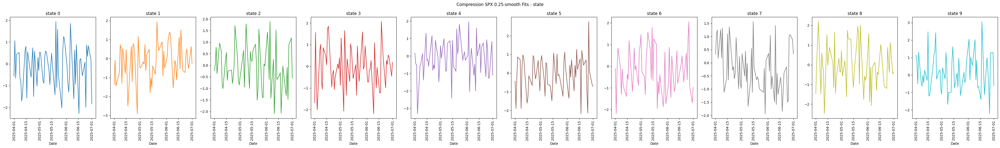

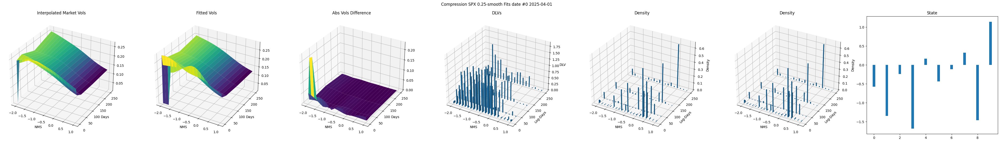

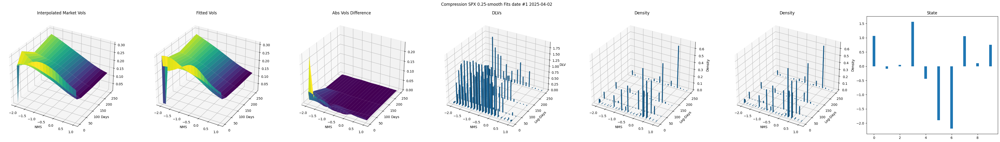

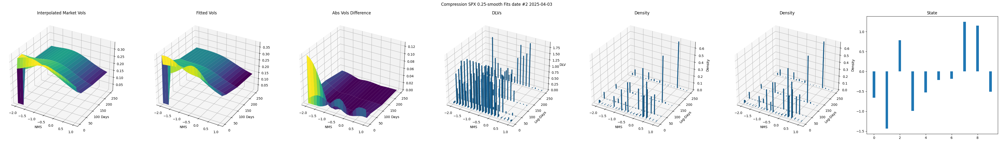

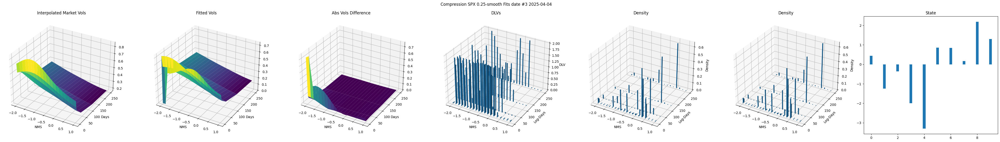

...

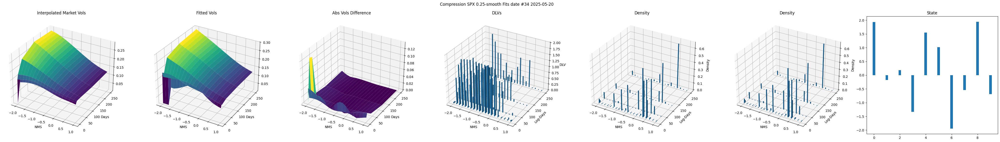

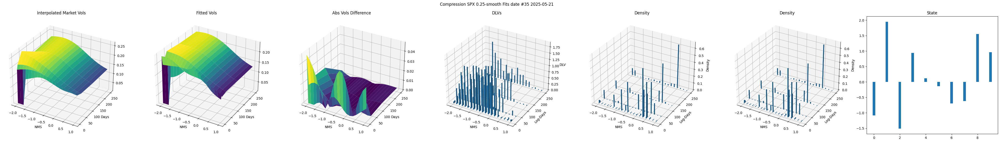

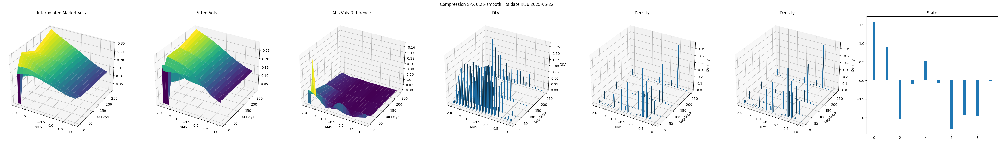

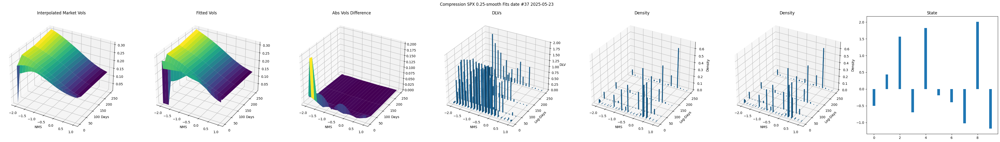

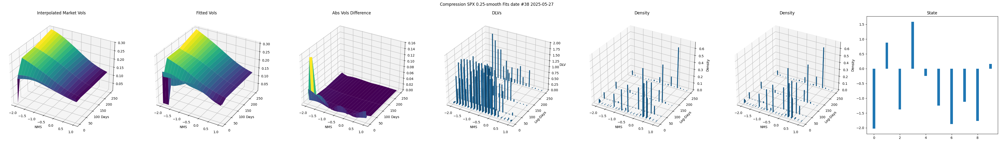

Exception ignored in: <function _xla_gc_callback at 0x0000019127E516C0>
Traceback (most recent call last):
  File "c:\Users\Public\venv\vqdata\Lib\site-packages\jax\_src\lib\__init__.py", line 123, in _xla_gc_callback
    xla_client._xla.collect_garbage()
KeyboardInterrupt: 


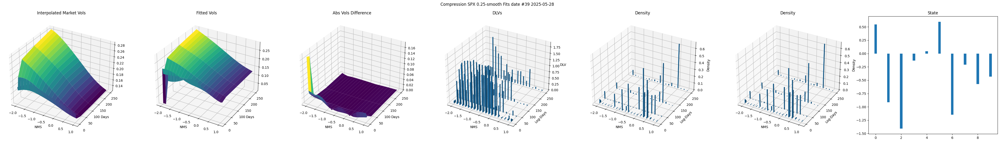

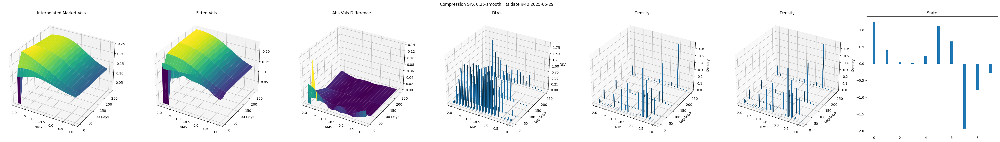

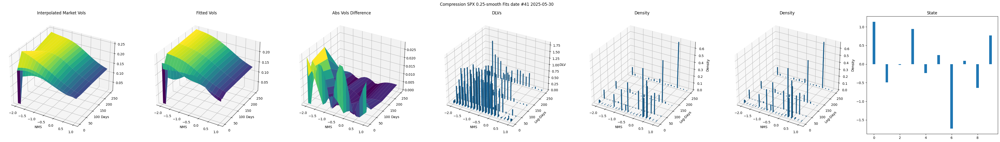

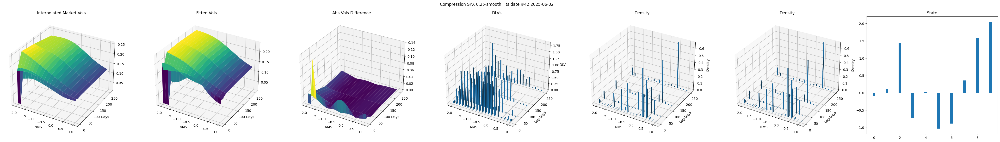

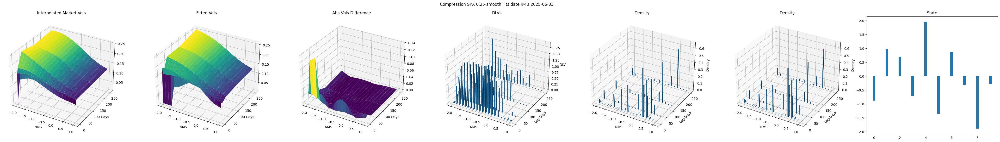

...

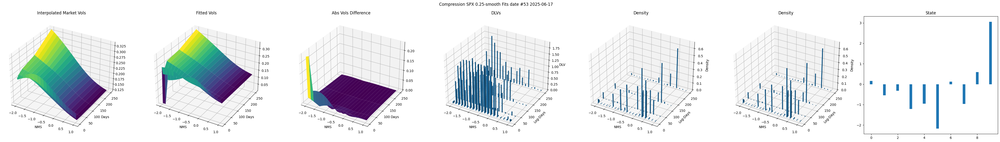

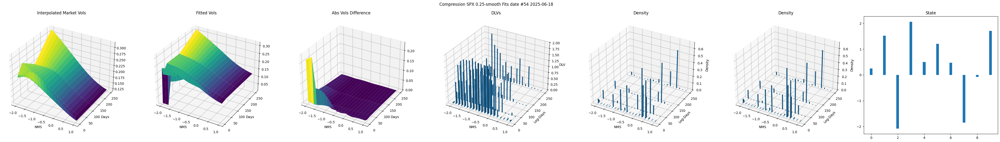

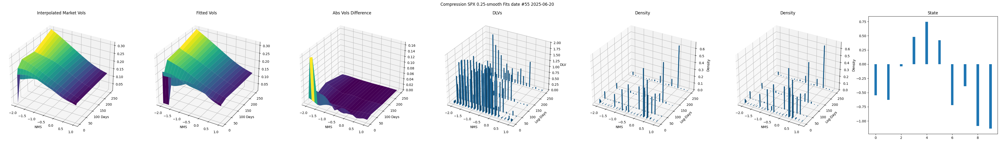

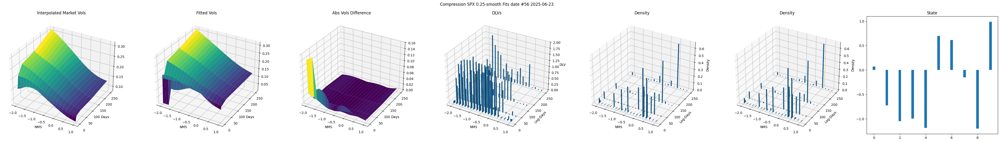

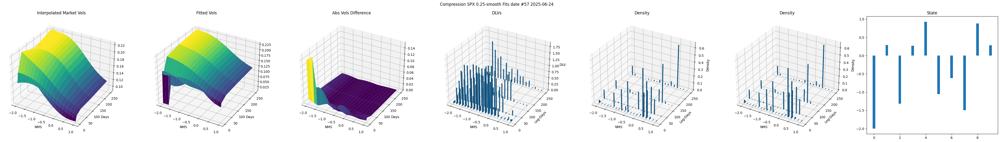

In [ ]:
def display(ticker, benchmark_config):
    str_smooth = f"{benchmark_config.smoothness:.2f}-smooth" if benchmark_config.smoothness is not None else "Linear"

    dates   = ts['dates']
    S, T, N = ts['mids'].shape
    state   = compressor.dlv_state.detach().cpu().numpy()

    with figure(f"Compression {ticker} {str_smooth} Fits - state", col_size=4, row_size=6, columns=state.shape[1] ) as fig:
        colors = colors_tableau()
        for istate in range(state.shape[1]):
            ax = fig.add_subplot(f"state {istate}")
            ax.plot(dates, state[:,istate], color=next(colors))
            ax.set_xlabel("Date")
            ax.tick_params(axis="x", labelrotation=90)

    for ix, d in enumerate(dates):
        with figure(f"Compression {ticker} {str_smooth} Fits date #{ix} {d}", col_size=6, row_size=6, columns=None ) as fig:

            final_calls_t = final_calls[ix,:,:]
            expiries_t    = ts['expiries'][ix,:]
            xstrikes_t    = ts['xstrikes'][ix,:,:]
            mids_t        = ts['mids'][ix,:,:]
            nms_t         = ts['nms'][ix,:]
            mid_vols_t    = ts['mid_vols'][ix,:,:]
            strikes_t     = xstrikes_t[:,1:-1]
            final_vols_t  = bs.implied( k=strikes_t, prices=final_calls_t, sqrtT=np.sqrt(expiries_t[:,None]) )


            X, Y = np.meshgrid(nms_t, expiries_t*DAYS_PER_YEAR)
            ax = fig.add_subplot("Interpolated Market Vols", projection="3d")
            ax.plot_surface(X, Y, mid_vols_t, cmap='viridis', edgecolor='none')
            ax.set_ylabel("Days")
            ax.set_xlabel("NMS")

            X, Y = np.meshgrid(nms_t, expiries_t*DAYS_PER_YEAR)
            ax = fig.add_subplot("Fitted Vols", projection="3d")
            ax.plot_surface(X, Y, final_vols_t, cmap='viridis', edgecolor='none')
            ax.set_ylabel("Days")
            ax.set_xlabel("NMS")

            X, Y = np.meshgrid(nms_t, expiries_t*DAYS_PER_YEAR)
            ax = fig.add_subplot("Abs Vols Difference", projection="3d")
            ax.plot_surface(X, Y, np.abs(final_vols_t - mid_vols_t), cmap='viridis', edgecolor='none')
            ax.set_ylabel("Days")
            ax.set_xlabel("NMS")
            ax.set_zlim( 0., 0.05 )

            ax = fig.add_subplot("DLVs", projection="3d")
            x = np.reshape(nms_t[None,:] + strikes_t*0.,(-1,))
            y = np.reshape((expiries_t*DAYS_PER_YEAR)[:,None] + strikes_t*0.,(-1,))
            z = np.reshape(np.sqrt(dlvsqs[ix,:,:]),(-1,))
            dx = (x.max() - x.min())/100.
            dy = (y.max() - y.min())/100.
            p = ax.bar3d(x=x, y=y, z=0.*z, dx=dx, dy=dy, dz=z, cmap="viridis", edgecolor='none' )
            ax.set_xlabel("NMS")
            ax.set_ylabel("Log-Days")
            ax.set_zlabel("DLV")

            ax = fig.add_subplot("Density", projection="3d")
            x = np.reshape(nms_t[None,:] + strikes_t*0.,(-1,))
            y = np.reshape((expiries_t*DAYS_PER_YEAR)[:,None] + strikes_t*0.,(-1,))
            z = np.reshape(xdensities[ix,:,1:-1],(-1,))
            dx = (x.max() - x.min())/100.
            dy = (y.max() - y.min())/100.
            p = ax.bar3d(x=x, y=y, z=0.*z, dx=dx, dy=dy, dz=z, cmap="viridis", edgecolor='none' )
            ax.set_xlabel("NMS")
            ax.set_ylabel("Log-Days")
            ax.set_zlabel("Density")

            ax = fig.add_subplot("Density", projection="3d")
            x = np.reshape(nms_t[None,:] + strikes_t*0.,(-1,))
            y = np.reshape((expiries_t*DAYS_PER_YEAR)[:,None] + strikes_t*0.,(-1,))
            z = np.reshape(xdensities[ix,:,1:-1],(-1,))
            dx = (x.max() - x.min())/100.
            dy = (y.max() - y.min())/100.
            p = ax.bar3d(x=x, y=y, z=0.*z, dx=dx, dy=dy, dz=z, cmap="viridis", edgecolor='none' )
            ax.set_xlabel("NMS")
            ax.set_ylabel("Log-Days")
            ax.set_zlabel("Density")

            ax = fig.add_subplot("State")
            ax.bar( np.arange(state.shape[-1]), state[ix,:], width=0.2 )


display( "SPX", benchmark_config )
